In [1]:
import os, glob
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from tqdm import tqdm

In [2]:

levels = ['8m', '16m', '47m', '80m', '140m', '200m', '280m']
#data_path = r"D:\!Work\IFA\!data\Urban_fluxes_NE\raw\Beijing\2024.6\Beijing tower"
data_path = r"D:\!Work\IFA\!data\Urban_fluxes_NE\raw\Beijing\*\Beijing tower"


df4levels = {}

for level in levels:
    files = glob.glob(os.path.join(data_path + '\\' + level, "*.txt"))
    df = pd.DataFrame()
    for file in tqdm(files):
        cur_df = pd.read_csv(file, sep='\t', skiprows=range(1,2), parse_dates={'date_full':['date', 'time']}).set_index('date_full')    
        df = pd.concat((df, cur_df))

    df['Tau'] = df['air_density'] * df['u*']**2

    df4levels[level] = df

  0%|          | 0/92 [00:00<?, ?it/s]C:\Users\mvar9\AppData\Local\Temp\ipykernel_21004\1951974323.py:12: FutureWarning: Support for nested sequences for 'parse_dates' in pd.read_csv is deprecated. Combine the desired columns with pd.to_datetime after parsing instead.
  cur_df = pd.read_csv(file, sep='\t', skiprows=range(1,2), parse_dates={'date_full':['date', 'time']}).set_index('date_full')
C:\Users\mvar9\AppData\Local\Temp\ipykernel_21004\1951974323.py:12: FutureWarning: Support for nested sequences for 'parse_dates' in pd.read_csv is deprecated. Combine the desired columns with pd.to_datetime after parsing instead.
  cur_df = pd.read_csv(file, sep='\t', skiprows=range(1,2), parse_dates={'date_full':['date', 'time']}).set_index('date_full')
C:\Users\mvar9\AppData\Local\Temp\ipykernel_21004\1951974323.py:12: FutureWarning: Support for nested sequences for 'parse_dates' in pd.read_csv is deprecated. Combine the desired columns with pd.to_datetime after parsing instead.
  cur_df = pd.r

<Axes: xlabel='date_full'>

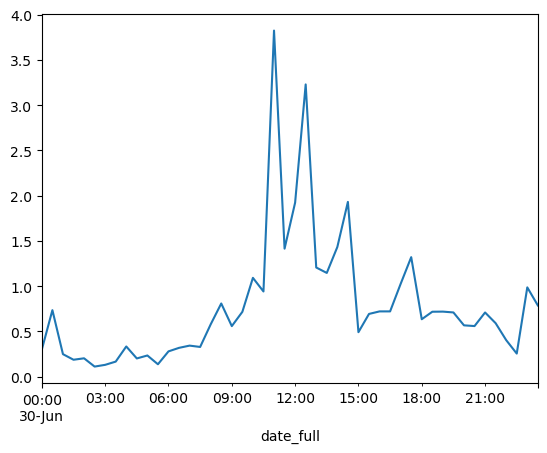

In [3]:
(cur_df['w_var'] / cur_df['u*']).plot()

<Axes: xlabel='date_full'>

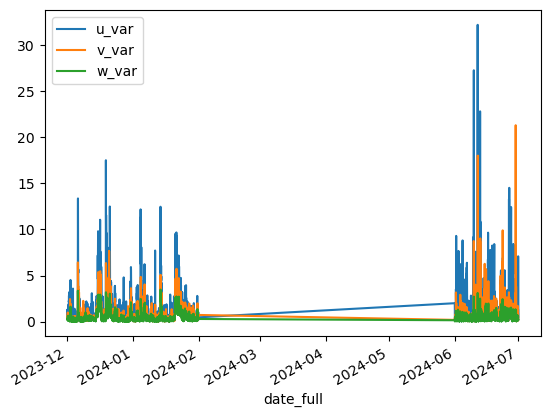

In [6]:
df4levels['140m'][['u_var', 'v_var', 'w_var']].plot()

In [7]:
export_dir = "D:/!Work/IFA/!data/Urban_fluxes_NE/processed/Beijing" 

time_shift = pd.Timedelta(8, 'h')

os.makedirs(export_dir, exist_ok=True)

for level in df4levels.keys():
    df4level = df4levels[level]
    df4level['u_sigma'] = np.sqrt(df4level['u_var'])
    df4level['v_sigma'] = np.sqrt(df4level['v_var'])
    df4level['w_sigma'] = np.sqrt(df4level['w_var'])
    
    df2export = df4level[['H', 'LE', 'Tau', 'u*', 'air_temperature', 'RH', 'air_pressure', 'air_density', 'v_unrot', 'u_unrot', 'w_unrot', 'wind_speed', 'u_sigma', 'v_sigma', 'w_sigma', 'wind_dir', 'co2_flux']] #, 'uz', 't', 'r', 'P', 'ro', 'u', 'v', 'w', 'V', 'D', 'alfa']]
    df2export.index.set_names('datetime_utc', inplace=True)

    
    df2export = df2export.rename(columns = {'H': 'Qh',
                                            'LE': 'Qle',
                                            'Tau': 'Qtau',
                                            'u*':'Ustar', 
                                            'air_temperature': 'T_air',
                                            'RH': 'RH_air',
                                            'air_pressure': 'P_air',
                                            'air_density': 'Rho_air',
                                            'v_unrot':'Wind_V',
                                            'u_unrot':'Wind_U',
                                            'w_unrot':'Wind_W',
                                            'wind_speed':'Wind_vel',
                                            'u_sigma':'Wind_U_std',
                                            'v_sigma':'Wind_V_std',                                
                                            'w_sigma':'Wind_W_std',
                                            'wind_dir':'Wind_dir',
                                            'co2_flux':'Qco2',
                                            })
    df2export.index = df2export.index - time_shift
    df2export.to_csv(export_dir + '/' + 'Beijing' + '_' + level +  '.csv')

    